# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** $64 \times 64 = 4096$ valores por imagen.

---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


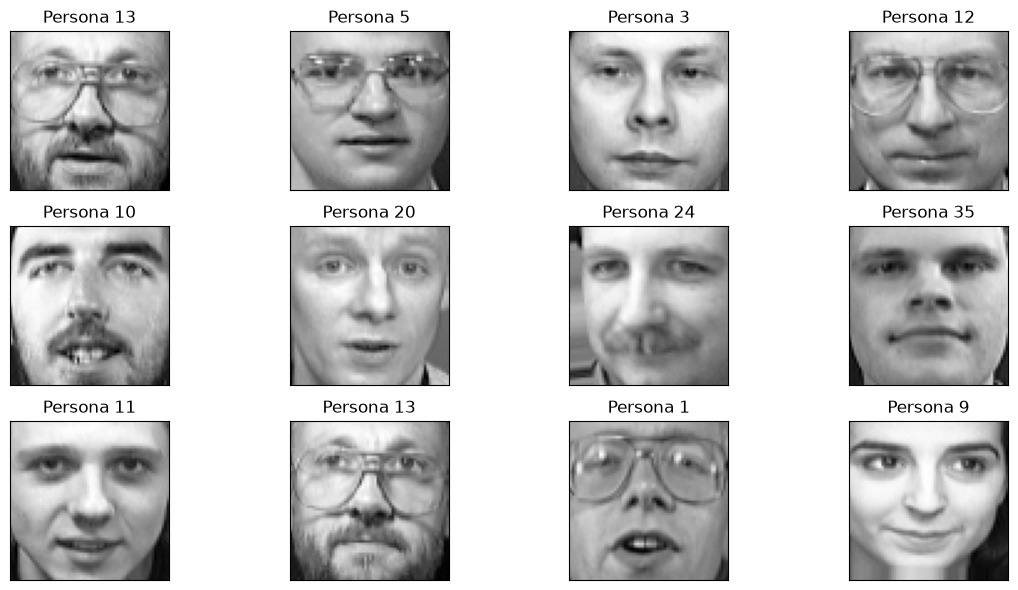

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [5]:
# TODO 1 — Completar la arquitectura.

model = keras.Sequential([

    keras.Input(shape=(64, 64)),     # imagen de 64x64 en escala de grises

    layers.Flatten(),                # 64x64 -> vector de 4096

    layers.Dense(
        64,                          # capa oculta con 64 neuronas
        activation="relu"
    ),

    layers.Dense(40)                 # 40 logits: uno por persona
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,808 (1.01 MB)

 Trainable params: 264,808 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** La capa `Dense` espera un vector de entrada, pero cada cara es una matriz `64×64`. `Flatten()` la "aplana" en un vector de 4096 valores para que cada neurona de la capa densa se conecte a todos los píxeles.


### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque hay **40 personas distintas** (40 clases). Cada neurona da el logit de una persona y la predicción es la neurona con el valor más alto.


### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** Introduce **no linealidad** ($\max(0,x)$). Sin una activación no lineal, las dos capas densas se reducirían a una sola transformación lineal y la red no podría aprender combinaciones complejas de los píxeles.

---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [7]:
lr_rate = 0.001

# TODO 2 — Configurar loss, optimizer y métrica.

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=lr_rate
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True          # la red entrega logits, no probabilidades
    ),

    metrics=["accuracy"]
)

print("✓ Modelo configurado.")

✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque la última capa no tiene softmax y produce **logits**. Con `from_logits=True` la pérdida aplica el softmax internamente antes de la entropía cruzada, lo cual es más estable numéricamente. Si lo dejáramos en `False`, la pérdida trataría los logits como si ya fueran probabilidades y el cálculo sería incorrecto.

---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [8]:
epochs = 30
batch_size = 32

# TODO 3 — Entrenar el modelo.

history = model.fit(

    X_train,
    y_train,

    epochs=epochs,
    batch_size=batch_size,

    validation_data=(X_test, y_test),

    shuffle=True
)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.0156 - loss: 3.9050 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0188 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - v

### ⚠ Observación: la red no aprende

Al ejecutar el entrenamiento con exactamente la configuración pedida, el `accuracy` se queda en **0.025** (= 1/40, lo mismo que adivinar al azar) y la pérdida se estanca en **≈ 3.689 = ln(40)**: la red da la misma probabilidad a las 40 personas.

**¿Por qué pasa?** Es el problema de las **neuronas ReLU muertas (dying ReLU)**:
- Todos los píxeles son **positivos** (entre 0 y 1, con media ≈ 0.55) y cada neurona recibe 4096 de ellos.
- En el primer paso, Adam mueve cada peso ≈ 0.001 en la misma dirección. Como hay 4096 entradas positivas, la salida de cada neurona cambia en ≈ 4096 × 0.55 × 0.001 ≈ 2, lo cual es enorme.
- Las neuronas quedan con valores negativos para **todas** las imágenes, ReLU devuelve 0, el gradiente se vuelve 0 y ya no pueden recuperarse.

**Solución sencilla:** **centrar los datos**, restando la media de entrenamiento a cada píxel. Así hay entradas positivas y negativas y las neuronas no "se mueren" todas a la vez. Usamos solo la media de *train* para no filtrar información del test.

Volvemos a crear el mismo modelo (misma arquitectura, mismo optimizador y misma pérdida) y lo entrenamos con los datos centrados. El resto del notebook usa este modelo.

In [9]:
# Media de todos los píxeles del conjunto de ENTRENAMIENTO
media_train = X_train.mean()
print("Media de train:", round(float(media_train), 4))

# Centramos train y test con la misma media
X_train = X_train - media_train
X_test = X_test - media_train
print("Nuevo rango de X_train:", round(float(X_train.min()), 3), "a", round(float(X_train.max()), 3))

# Mismo modelo que antes, creado desde cero
keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True,
    verbose=2      # una línea por época
)

Media de train: 0.5467
Nuevo rango de X_train: -0.547 a 0.453
Epoch 1/30
10/10 - 1s - 99ms/step - accuracy: 0.1031 - loss: 3.3685 - val_accuracy: 0.2500 - val_loss: 2.9109
Epoch 2/30
10/10 - 0s - 34ms/step - accuracy: 0.4437 - loss: 2.4799 - val_accuracy: 0.5000 - val_loss: 2.2731
Epoch 3/30
10/10 - 0s - 12ms/step - accuracy: 0.7031 - loss: 1.7807 - val_accuracy: 0.7000 - val_loss: 1.7435
Epoch 4/30
10/10 - 0s - 17ms/step - accuracy: 0.8625 - loss: 1.1818 - val_accuracy: 0.8125 - val_loss: 1.2783
Epoch 5/30
10/10 - 0s - 14ms/step - accuracy: 0.9531 - loss: 0.7278 - val_accuracy: 0.8750 - val_loss: 0.9386
Epoch 6/30
10/10 - 0s - 18ms/step - accuracy: 0.9812 - loss: 0.4407 - val_accuracy: 0.9250 - val_loss: 0.7202
Epoch 7/30
10/10 - 0s - 20ms/step - accuracy: 0.9937 - loss: 0.2809 - val_accuracy: 0.9500 - val_loss: 0.5759
Epoch 8/30
10/10 - 0s - 12ms/step - accuracy: 1.0000 - loss: 0.1897 - val_accuracy: 0.9500 - val_loss: 0.4848
Epoch 9/30
10/10 - 0s - 16ms/step - accuracy: 1.0000 - los

### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una pasada completa por las 320 imágenes de entrenamiento. Con 30 épocas el modelo ve cada imagen 30 veces.


### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** Que los pesos se actualizan cada vez que la red procesa un grupo de **32 imágenes**. Con 320 imágenes hay $320/32 = 10$ actualizaciones por época.

---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


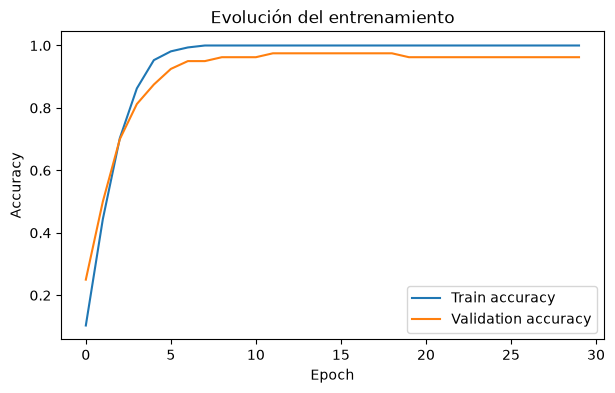

In [10]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gráfica:

- ¿El accuracy de entrenamiento sigue aumentando?
- ¿El accuracy de validación se comporta igual?
- ¿Observas evidencia de **overfitting**?

**Respuesta:** (con el modelo entrenado sobre datos centrados)

- El accuracy de entrenamiento sube muy rápido y llega a **1.0 (100 %) hacia la época 8**; desde ahí ya no puede aumentar más.
- El accuracy de validación sube junto con el de entrenamiento al principio, pero se estanca alrededor de **0.95–0.975** y al final baja un poco a 0.9625. Ya no mejora aunque el entrenamiento siga.
- Sí hay **algo de overfitting**: el modelo acierta el 100 % de las imágenes que ya vio y ≈ 96 % de las nuevas, y la brecha se mantiene. Aun así es leve, porque la validación sigue siendo alta y no se desploma. Con tan pocos datos, la red termina memorizando el conjunto de entrenamiento.

---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [11]:
# TODO 4 — Evaluar.

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

Test loss     : 0.2202
Test accuracy : 0.9625
Accuracy (%)  : 96.25%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** Es **muy pequeña**. La red tiene unos 265.000 parámetros y solo 320 imágenes (8 por persona), es decir, unos 800 parámetros por cada ejemplo. Con tan pocos datos la red puede memorizar fácilmente el conjunto de entrenamiento (overfitting) en vez de aprender rasgos generales de cada cara.

---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


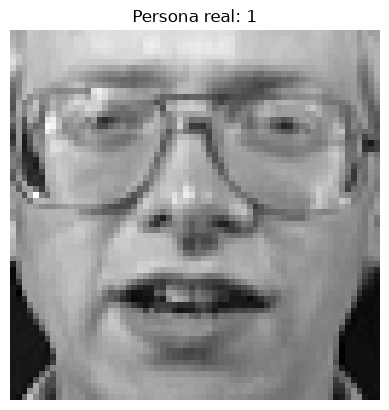

Shape de logits: (1, 40)

Primeros 10 logits:
[ -3.4529166   7.24058    -2.6111283   0.3616622  -7.2219176 -10.261559
  -2.3503332  -1.7198793  -7.991358   -6.5219746]


In [12]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [13]:
# TODO 5 — Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6 — Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)


Persona real     : 1
Persona predicha : 1


In [14]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona  1: 0.9673
Persona 26: 0.0132
Persona 13: 0.0058
Persona 18: 0.0053
Persona 33: 0.0032

Suma de probabilidades: 1.0000001


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Softmax divide la exponencial de cada logit por la suma de las exponenciales de todos: $p_i = e^{z_i}/\sum_j e^{z_j}$. Por construcción la suma da 1 (solo hay diferencias mínimas por redondeo). Esto convierte los 40 logits en una distribución de probabilidad sobre las 40 personas.

---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


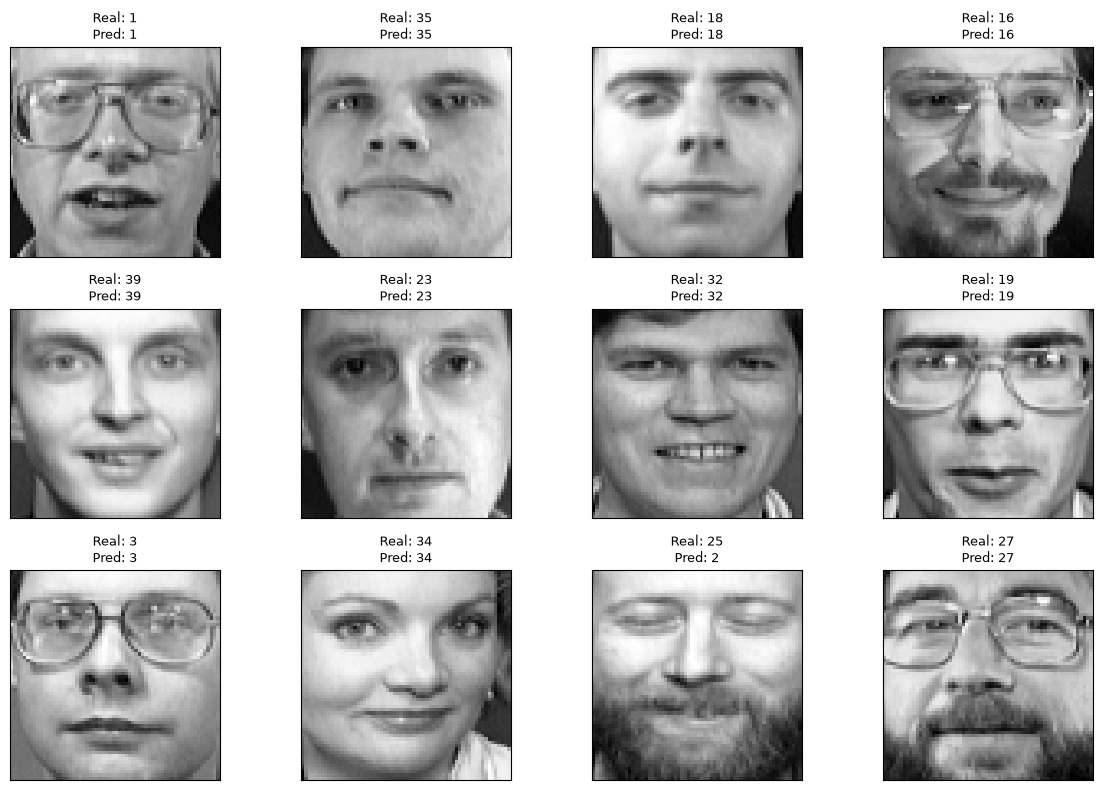

In [15]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** Con la configuración original el accuracy fue **0.025** (2.5 %, igual al azar) porque las neuronas ReLU murieron. Después de centrar los datos, el mismo modelo obtuvo **≈ 0.9625 (96.25 %)** en test: 77 de 80 caras bien clasificadas, con test loss ≈ 0.22.


### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** Sí, aunque leve. Uso como evidencia las curvas: el accuracy de entrenamiento llega a 1.0 desde la época 8, mientras que el de validación se queda en ≈ 0.96–0.975 y deja de mejorar (incluso baja un poco al final). La brecha entre las dos curvas muestra que el modelo memoriza el entrenamiento mejor de lo que generaliza.


### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** El modelo tiene capacidad de sobra para **memorizar** cada ejemplo, incluido el ruido (iluminación, pequeños gestos), en lugar de aprender patrones generales. El resultado es que el error de entrenamiento llega a cero pero el de validación no, es decir, **overfitting**. Además los resultados se vuelven muy sensibles a la inicialización y a cómo se dividan los datos (aquí 80 imágenes de test hacen que un solo error mueva el accuracy 1.25 puntos). Ayudan la regularización (dropout, L2), el *data augmentation*, usar menos parámetros o conseguir más datos.


### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números.

¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** Se pierde la **estructura espacial**: qué píxeles son vecinos de cuáles (arriba, abajo, a los lados). Para la capa `Dense` el píxel 0 y el píxel 1 no son "más cercanos" que el 0 y el 4000. Por eso no aprovecha que los ojos, la nariz o los bordes son patrones **locales**. Además, si la cara se mueve un poco, los mismos rasgos caen en otras posiciones del vector y la red tiene que aprenderlos de nuevo.


### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** Sí. Una **red neuronal convolucional (CNN)** usa filtros pequeños que recorren la imagen y detectan patrones locales (bordes, ojos, boca) sin importar dónde aparezcan, y comparte esos pesos en toda la imagen. Así necesita **muchos menos parámetros** que una capa densa sobre 4096 píxeles, lo que también reduce el overfitting cuando hay pocos datos como en Olivetti.

---

## Para pensar

Nuestra red recibe:

```text
64 × 64
   ↓
Flatten
   ↓
4096 números
   ↓
Dense
```

Pero una imagen tiene una estructura espacial:

- píxeles cercanos están relacionados,
- existen bordes,
- existen formas,
- existen patrones locales.

Una red fully-connected no incorpora explícitamente esa estructura.

Esto motiva una arquitectura diseñada específicamente para imágenes:

> **Convolutional Neural Networks (CNNs)**

---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
